# Model Workspace Knockout

Does writing reasoning down protect a model when its internal "workspace" is
knocked out? This notebook ablates the Jacobian-lens J-space of **Qwen3-4B**
on GSM8K → MATH-500 (levels 1–5) → AIME 2024, with and without chain of
thought. See the [README](README.md) for the hypotheses,
results and discussion.

The reusable code lives in [`jspace/`](jspace/) and is tested in
[`tests/`](tests/); this notebook only wires it together and holds the outputs.
Designed for a Colab A100. The runner is resumable, so a disconnect costs at
most one generation.

## 0. Setup

In [1]:
import os, sys

if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    WORK = "/content/drive/MyDrive/model-workspace-knockout"
    # Model/dataset cache on the VM's local disk: reading an 8 GB file back
    # through the Drive mount right after writing it can return a corrupt file.
    os.environ["HF_HOME"] = "/content/hf_cache"
else:
    WORK = os.getcwd()

os.environ.setdefault("HF_HOME", f"{WORK}/hf_cache")
sys.path[:0] = [WORK, f"{WORK}/jacobian-lens"]
for d in ["results", "figures"]:
    os.makedirs(f"{WORK}/{d}", exist_ok=True)

In [2]:
%pip install -q math-verify

import random
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import torch
import transformers
from datasets import load_dataset

import jlens
from jspace import Ablator, RunConfig, run_grid, calibration, plots
from jspace.ablation import concept_scores, effective_unembed, remove_jspace, remove_random_matched
from jspace.data import load_sample

In [3]:
SEED = 288
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

MODEL = "Qwen/Qwen3-4B"
# Pre-fitted lens from Neuronpedia (wikitext-103, early-stopped at 479 prompts)
LENS_REPO = "neuronpedia/jacobian-lens"
LENS_FILE = "qwen3-4b/jlens/Salesforce-wikitext/Qwen3-4B_jacobian_lens.pt"

## 1. Hypotheses

1. **The CoT gap widens with difficulty.** Harder problems need more
   intermediate results held somewhere. Without ablation, CoT's advantage over
   answering directly should grow from GSM8K → MATH L1–5 → AIME.
2. **Ablation hurts no-CoT more.** Once the reasoning is written down, removing
   the J-space shouldn't matter much. Without CoT, the model has nowhere else to
   keep it, so ablation should bite harder as problems get harder, as long as
   accuracy hasn't already hit the floor.

## 2. Model, lens, and sanity checks

In [4]:
hf_model = transformers.AutoModelForCausalLM.from_pretrained(
    MODEL, dtype=torch.bfloat16
).cuda()
tokenizer = transformers.AutoTokenizer.from_pretrained(MODEL)
model = jlens.from_hf(hf_model, tokenizer)
model

HFLensModel(Qwen3ForCausalLM, n_layers=36, d_model=2560)

In [5]:
jlens.configure_logging()
LENS_LOCAL = f"{WORK}/lens/Qwen3-4B_jacobian_lens.pt"
lens = jlens.JacobianLens.from_pretrained(
    LENS_LOCAL if os.path.exists(LENS_LOCAL) else LENS_REPO,
    filename=LENS_FILE,
)
lens

JacobianLens(d_model=2560, n_prompts=479, source_layers=[0..34] (35 layers))

### What the lens sees

Top-5 lens readout at the last token, per layer. On the boot prompt, *Italy*
shows up around L23 and *euro* takes over by L29, even though neither word
is in the prompt. That puts Qwen's workspace later than the paper's model,
which matters for where we ablate.

In [6]:
VERIF = [
    "Fact: The currency used in the country shaped like a boot is",
    "The number of legs on the animal that spins webs is",
]
for prompt in VERIF:
    print(f"\n=== {prompt!r}")
    lens_logits, _, _ = lens.apply(model, prompt, positions=[-1])
    for layer in sorted(lens_logits):
        top5 = [tokenizer.decode([t]) for t in lens_logits[layer][0].topk(5).indices]
        print(f"  L{layer:2d}: {top5}")


=== 'Fact: The currency used in the country shaped like a boot is'
  L 0: [' –', ' …\n\n', ' ….', '….\n\n', '”.\n\n']
  L 1: [' …\n\n', ' *\n\n', " ''\n\n", ' $\n\n', ' ”\n\n']
  L 2: ['…\n', ' …\n\n', '…\n\n', ' …', '*\n']
  L 3: ['…”', '”\n', '.”\n', '…”\n\n', '”，']
  L 4: ['”.\n\n', '’.\n\n', '”。\n\n', '…”\n\n', '`.\n\n']
  L 5: ['”。\n\n', '”.\n\n', '”，', '`.\n\n', ' –']
  L 6: ['`.\n\n', '”。\n\n', '`\n\n', '`.\n', '。\n\n']
  L 7: ['`.\n\n', '”。\n\n', '`\n\n', ' \\`', '`;\n\n']
  L 8: ['`.\n\n', '`.\n', '`;\n\n', ' \\`', '”。\n\n']
  L 9: [' \\`', '`.\n\n', '`.\n', '`;\n\n', '帼']
  L10: [' \\`', ' &#', '帼', '`.\n\n', ' $\n\n']
  L11: [' \\`', ' &#', '帼', ' recognised', 'colour']
  L12: [' \\`', '`.\n\n', '`.\n', ' […', ' Britain']
  L13: ['colour', ' recognised', '。\n', ' colour', ' humour']
  L14: ['，', '。\n', '`.\n', '`.\n\n', '。\n\n']
  L15: ['吗', '。\\', '？\n', ' \\`', '哪个']
  L16: ['？”', '?”\n\n', '?’', '”?', '？\n']
  L17: ['？\n\n', '？\n', '?\n\n', '?”\n\n', ')?\n\n']
  L18: ['？

### Our scorer matches the reference implementation

In [7]:
ablator = Ablator(hf_model, lens.jacobians, seed=SEED)
DEVICE = ablator.device
print(f"lens covers layers {lens.source_layers[0]}–{lens.source_layers[-1]} "
      f"({len(lens.source_layers)} of {hf_model.config.num_hidden_layers})")

CHECK_PROMPT = "Fact: The currency used in the country shaped like a boot is"
CHECK_LAYER = 23

lens_logits, _, _ = lens.apply(model, CHECK_PROMPT, layers=[CHECK_LAYER], positions=[-1])
package_top5 = lens_logits[CHECK_LAYER][0].topk(5).indices

with torch.no_grad(), jlens.ActivationRecorder(model.layers, at=[CHECK_LAYER]) as rec:
    model.forward(model.encode(CHECK_PROMPT))
h = rec.activations[CHECK_LAYER][0, -1:, :].float().cpu()
W_f32 = effective_unembed(hf_model, torch.float32).cpu()
manual_top5 = concept_scores(h, lens.jacobians[CHECK_LAYER], W_f32).topk(5).indices.flatten()

print("package:", tokenizer.convert_ids_to_tokens(package_top5.tolist()),
      "| ours:", tokenizer.convert_ids_to_tokens(manual_top5.tolist()))
assert set(manual_top5.tolist()) == set(package_top5.tolist()), "concept scores mismatch"

lens covers layers 0–34 (35 of 36)
package: ['æĦıå¤§åĪ©', 'Italy', 'ĠItaly', 'è¥¿çıŃçīĻ', 'æ¬§åħĥ'] | ours: ['æĦıå¤§åĪ©', 'Italy', 'ĠItaly', 'è¥¿çıŃçīĻ', 'æ¬§åħĥ']


### The ablation removes what it says it removes

After the edit, the selected concepts' lens scores should be ~0, and the
random control should remove exactly as much norm as the treatment.

In [8]:
K_CERT, N_CERT = 25, 10

with torch.no_grad(), jlens.ActivationRecorder(model.layers, at=[CHECK_LAYER]) as rec:
    model.forward(model.encode(CHECK_PROMPT))
h_chk = rec.activations[CHECK_LAYER].detach().float()

_, chk_model_logits, _ = lens.apply(model, CHECK_PROMPT, layers=[CHECK_LAYER], positions=[-1])
excl = chk_model_logits[0].topk(N_CERT).indices.to(DEVICE)
J_chk, W = ablator.J[CHECK_LAYER].float(), ablator.W

h_abl = remove_jspace(h_chk, J_chk, W, K_CERT, excl)
scores_pre = concept_scores(h_chk, J_chk, W).index_fill_(-1, excl, float("-inf"))
top = scores_pre.topk(K_CERT, dim=-1).indices
pre_vals = scores_pre.gather(-1, top)
post_vals = concept_scores(h_abl, J_chk, W).gather(-1, top)
print(f"selected-concept |score|: pre max {pre_vals.abs().max():.1f} "
      f"-> post max {post_vals.abs().max():.2e}")
assert post_vals.abs().max() < 1e-2 * pre_vals.abs().max(), "concepts not silenced"

treat_norm = (h_chk - h_abl).norm(dim=-1, keepdim=True)
h_ctl = remove_random_matched(h_chk, ablator.random_basis(CHECK_LAYER, K_CERT), treat_norm)
ctl_norm = (h_chk - h_ctl).norm(dim=-1, keepdim=True)
print(f"control/treatment removal-norm ratio: "
      f"mean {(ctl_norm / treat_norm.clamp_min(1e-6)).mean():.4f}")
assert torch.allclose(ctl_norm, treat_norm, rtol=1e-2), "control norm not matched"
print("ablation ops certified")

selected-concept |score|: pre max 1698.1 -> post max 1.99e-03
control/treatment removal-norm ratio: mean 1.0000
ablation ops certified


## 3. Calibrating the ablation on Qwen3-4B

Before touching any dataset, the ablation has to reproduce the paper's own validity
check (their Fig. 22): two-hop questions whose bridge entity is never written
("the animal that spins webs" → spider → 8). J-space ablation should break
these; a norm-matched random ablation shouldn't. Without this, a null result
on the datasets would be uninterpretable.

The table changes one thing per row: the paper's settings mapped directly
onto Qwen, then bands re-centred on Qwen's workspace, then the exclusion set
N narrowed from 10 → 5 → 3.

In [9]:
PAPER_BAND = list(range(19, 29))
LIGHT, MEDIUM, HEAVY = list(range(27, 29)), list(range(26, 30)), list(range(24, 33))
CAL_K = 25

WIKI = [t for t in load_dataset("Salesforce/wikitext", "wikitext-103-raw-v1",
                                split="train")["text"] if len(t) > 400][:30]

def pt(band, mode):
    return calibration.pt_match(hf_model, tokenizer, ablator, WIKI, band, mode, CAL_K)

def mh(band, mode, k=0, n=0):
    return calibration.multihop_acc(hf_model, tokenizer, ablator, band, mode, k, n)

# Ablation strength: prompt-token top-1 agreement with the clean model
print(f"PT top-1 match (jspace, k={CAL_K})   [paper tiers at its k=10: .87/.75/.65; random .96]")
for name, band in [("light 27-28", LIGHT), ("medium 26-29", MEDIUM), ("heavy 24-32", HEAVY)]:
    print(f"  {name:14s}: {pt(band, 'jspace'):.3f}")
print(f"  {'random@heavy':14s}: {pt(HEAVY, 'random'):.3f}")

# Multihop dose-response
print(f"\nclean multihop = {mh([], 'none'):.2f}")
print(f"{'config':36s} multihop  random")
for name, band, k, n in [
    ("paper mapping (19-28, k10, N10)", PAPER_BAND, 10, 10),
    ("light 27-28   (k25, N10)",  LIGHT,  CAL_K, 10),
    ("medium 26-29  (k25, N10)",  MEDIUM, CAL_K, 10),
    ("heavy 24-32   (k25, N10)",  HEAVY,  CAL_K, 10),
    ("light 27-28   (k25, N5)",   LIGHT,  CAL_K, 5),
    ("medium 26-29  (k25, N5)",   MEDIUM, CAL_K, 5),
    ("heavy 24-32   (k25, N5)",   HEAVY,  CAL_K, 5),
    ("light 27-28   (k25, N3)",   LIGHT,  CAL_K, 3),
    ("medium 26-29  (k25, N3)",   MEDIUM, CAL_K, 3),
    ("heavy 24-32   (k25, N3)",   HEAVY,  CAL_K, 3),
]:
    print(f"{name:36s}   {mh(band, 'jspace', k, n):.2f}     {mh(band, 'random', k, n):.2f}")

PT top-1 match (jspace, k=25)   [paper tiers at its k=10: .87/.75/.65; random .96]
  light 27-28   : 0.765
  medium 26-29  : 0.726
  heavy 24-32   : 0.623
  random@heavy  : 0.756

clean multihop = 0.83
config                               multihop  random
paper mapping (19-28, k10, N10)        0.92     0.83
light 27-28   (k25, N10)               0.75     0.75
medium 26-29  (k25, N10)               0.75     0.75
heavy 24-32   (k25, N10)               0.58     0.75
light 27-28   (k25, N5)                0.83     0.75
medium 26-29  (k25, N5)                0.83     0.75
heavy 24-32   (k25, N5)                0.58     0.75
light 27-28   (k25, N3)                0.83     0.75
medium 26-29  (k25, N3)                0.75     0.75
heavy 24-32   (k25, N3)                0.50     0.75


### Frozen configuration

- **Bands.** Re-centred on Qwen's workspace (L22–34 in the readouts above).
  Medium (26–29) and heavy (24–32) keep the paper's two smaller band widths;
  light (27–28) is a narrower, weaker tier.
- **N = 3**, down from the paper's 10. On short prompts the clean top-10
  already contains the intermediates ("spider" is rank 2), so excluding them
  protects exactly what we want to remove. Shrinking N makes heavy ablation
  bite (0.83 → 0.50) while the random control stays flat at 0.75.
- **k = 25** directions per position, up from 10.

These are fixed from here on and used unchanged for every dataset.

In [10]:
BANDS = {"light": LIGHT, "medium": MEDIUM, "heavy": HEAVY}

# CoT caps leave headroom above correct clean-solution lengths (MATH p99 ~2.1k,
# longest correct AIME ~1.9k tokens). LoopStop catches degenerate repetition,
# so caps only bind on genuinely long answers.
# no-CoT grades the first line only; 128 leaves room to see what leaks after it.
cfg = RunConfig(hf_model, tokenizer, ablator, BANDS, k=25, n_exclude=3,
                max_tokens_no_cot=128,
                max_tokens_cot={"gsm8k": 1024, "math500": 4096, "aime24": 6144})

print("frozen:", {k: (v[0], v[-1]) for k, v in BANDS.items()},
      "| k =", cfg.k, "| N =", cfg.n_exclude)

frozen: {'light': (27, 28), 'medium': (26, 29), 'heavy': (24, 32)} | k = 25 | N = 3


## 4. Data

150 GSM8K, 150 MATH-500 (30 per level), all 30 AIME 2024 problems. The ids
are drawn once (seed 288) and frozen in `artifacts/sample_ids.json`, so every
condition is scored on the same problems and comparisons are paired.

Grading: GSM8K/AIME by numeric equality on the first number in the answer;
MATH-500 by `math-verify` symbolic equivalence with a string fallback. The
grader is unit-tested in `tests/test_grading.py`, and `tests/test_results.py`
re-grades every stored row.

In [11]:
DATA_GSM8K, DATA_MATH, DATA_AIME = load_sample(f"{WORK}/artifacts/sample_ids.json", seed=SEED)
ALL_DATA = DATA_GSM8K + DATA_MATH + DATA_AIME
print(Counter(x["dataset"] for x in ALL_DATA))
print("math500 per level:", Counter(x["level"] for x in DATA_MATH))
print("example gsm8k answer:", DATA_GSM8K[0]["answer"],
      "| math500:", DATA_MATH[0]["answer"], "| aime:", DATA_AIME[0]["answer"])

Counter({'gsm8k': 150, 'math500': 150, 'aime24': 30})
math500 per level: Counter({1: 30, 2: 30, 3: 30, 4: 30, 5: 30})
example gsm8k answer: 125 | math500: 4 | aime: 204


## 5. Experiments

Five conditions × two arms. Each `run_grid` call appends to the dataset's
CSV and skips rows already there. Greedy decoding throughout; thinking mode
off in both arms.

MATH-500 CoT runs on a 50-problem subset (10 per level) to keep GPU time
manageable; no-CoT runs on all 150.

In [12]:
CONDITIONS = ["clean", "light", "medium", "heavy", "random"]

def run_all(data, arm, name):
    for cond in CONDITIONS:
        run_grid(data, cond, arm, f"{WORK}/results/{name}.csv", cfg)

run_all(DATA_GSM8K, "no_cot", "gsm8k")
run_all(DATA_GSM8K, "cot", "gsm8k")

In [13]:
rng = random.Random(SEED)
MATH50 = [ex for lvl in sorted({e["level"] for e in DATA_MATH})
          for ex in rng.sample([e for e in DATA_MATH if e["level"] == lvl], 10)]

run_all(DATA_MATH, "no_cot", "math500")
run_all(MATH50, "cot", "math500")

In [14]:
run_all(DATA_AIME, "no_cot", "aime24")
run_all(DATA_AIME, "cot", "aime24")

## 6. Analysis

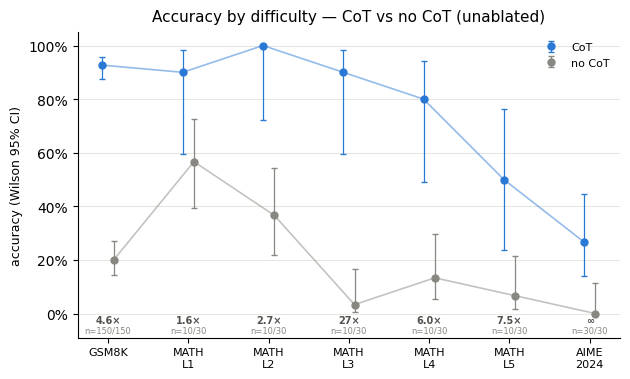

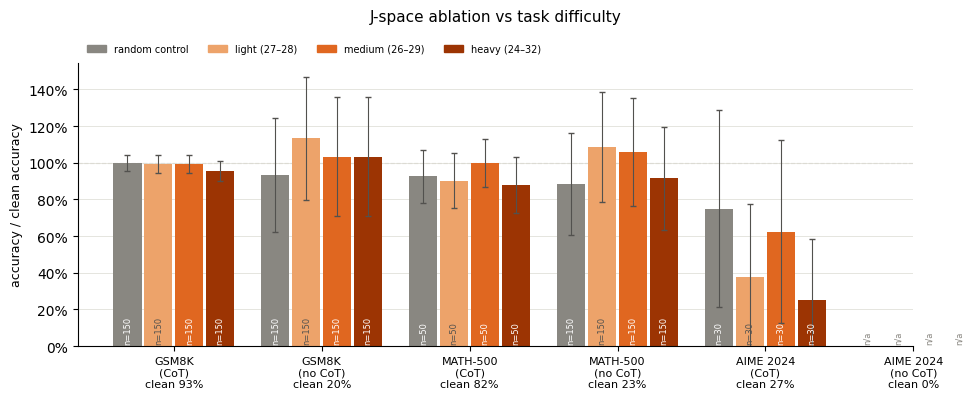

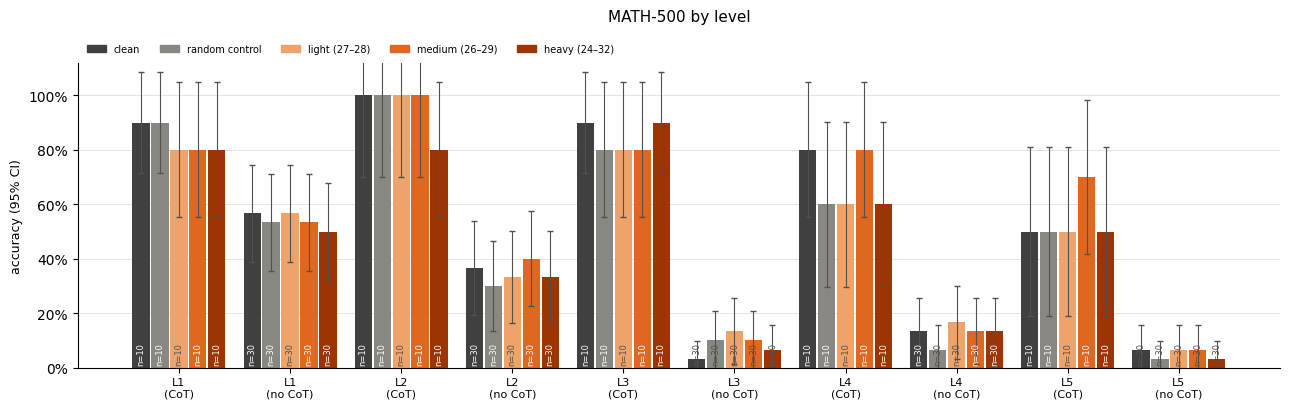

In [15]:
res = plots.load_results(f"{WORK}/results")
plots.fig_cot_gap(res, f"{WORK}/figures/cot_gap.png"); plt.show()
plots.fig_ablation_vs_difficulty(res, f"{WORK}/figures/ablation_vs_difficulty.png"); plt.show()
plots.fig_math_levels(res, f"{WORK}/figures/math500_levels.png"); plt.show()

Paired exact McNemar test of every ablation against its own arm's clean run.
`lost` = problems clean got right and the ablated run got wrong; `gained` is
the reverse.

In [16]:
plots.mcnemar_table(res)

,dataset,arm,condition,n,clean,ablated,lost,gained,p
0,gsm8k,cot,random,150,0.927,0.927,5,5,1.000
1,gsm8k,cot,light,150,0.927,0.920,6,5,1.000
2,gsm8k,cot,medium,150,0.927,0.920,4,3,1.000
3,gsm8k,cot,heavy,150,0.927,0.887,10,4,0.180
4,gsm8k,no_cot,random,150,0.200,0.187,6,4,0.754
5,gsm8k,no_cot,light,150,0.200,0.227,2,6,0.289
6,gsm8k,no_cot,medium,150,0.200,0.207,3,4,1.000
7,gsm8k,no_cot,heavy,150,0.200,0.207,5,6,1.000
8,math500,cot,random,50,0.820,0.760,4,1,0.375
9,math500,cot,light,50,0.820,0.740,4,0,0.125


**Takeaways.**

- *H1 holds where CoT is reliable.* The CoT/no-CoT gap grows from 4.6× on
  GSM8K to 27× at MATH L3. At AIME it closes again because CoT itself fails.
- *H2 does not hold.* On GSM8K and MATH-500, no ablation tier moves either
  arm. No-CoT barely changes even where it had room to fall.
- *The only real hit is AIME with CoT* (heavy: 27% → 7%, p = 0.03). But the
  random control also drops it (to 20%), and ablated AIME runs often collapse
  into repetition loops (23/30 under heavy vs 6/30 clean), so at n = 30 this
  can't be cleanly attributed to the workspace.